# Setup

In [3]:
from pathlib import Path
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

309 images trouvées


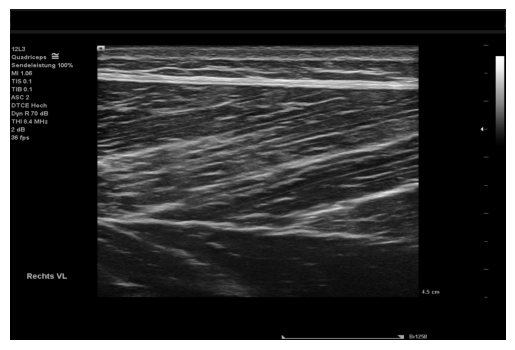

In [2]:
# Chercher les images de test
dossier = Path("data/test_images_v2")
images = [p for p in dossier.rglob("*")
          if p.suffix.lower() in (".png", ".tif", ".tiff")]

print(f"{len(images)} images trouvées")

# Afficher la première image
img = cv.imread(str(images[0]), cv.IMREAD_GRAYSCALE)

plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

# Retrait des bords

In [ ]:
def plage_principale(profil, seuil=5):
    # Lissage pour éviter les petites variations
    profil = np.convolve(profil, np.ones(31)/31, mode="same")

    # Détection des zones avec suffisamment de variations
    actif = profil > seuil

    # Recherche des débuts et fins des zones détectées
    transitions = np.diff(np.r_[False, actif, False].astype(int))
    debuts = np.where(transitions == 1)[0]
    fins = np.where(transitions == -1)[0]

    if len(debuts) == 0:
        return 0, len(profil)

    # On garde la zone continue la plus longue
    i = np.argmax(fins - debuts)

    return debuts[i], fins[i]
